In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
from plot_config import COLORS, FIG_W_SINGLE, FIG_W_DOUBLE, set_font_size
GRID = False
FONT_SIZE = 18
LEGEND_FONT_SIZE = FONT_SIZE * 0.75  # change to resize legend text only
set_font_size(FONT_SIZE, LEGEND_FONT_SIZE)

# Shared exported size (inches) for the energy bar chart and the X/Y tracking
# plots, so all three come out with identical dimensions -- TUNE THIS.
# Height = a 13:6 plot area plus a 0.42 in row on top for the tracking legends.
PANEL_W = FIG_W_SINGLE * 1.3
PANEL_H = PANEL_W * 6 / 13 + 0.42

# Surface Tracking: Energy Consumption

Two stiffnesses tracking the same slanted-obstacle reference: k = 8 N/m (soft) vs
k = 70 N/m (stiff). Energy is the actuators' total mechanical work — |tau · qdot|
summed over all 9 motors and integrated over the first 45 s — in joules.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import os
from scipy.integrate import trapezoid as trapz

# Soft vs stiff comparison
k_values = [8, 70]
data = {}

for k in k_values:
    fname = os.path.join('outputs', 'surface_tracking', f'k{k}.npz')
    d = np.load(fname)
    data[k] = d
    print(f"Loaded {fname}: {len(d['t'])} samples")

Loaded outputs\surface_tracking\k8.npz: 24719 samples
Loaded outputs\surface_tracking\k70.npz: 20399 samples


k=8: Energy (0-45s) = 0.22 J
k=70: Energy (0-45s) = 0.43 J


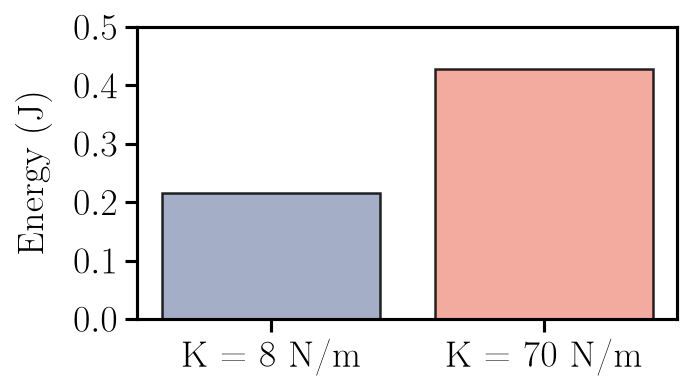


Energy ratio (stiff/soft): 1.98x


In [3]:
YLABEL_PAD = 10  # pt -- TUNE THIS: space between 'Energy (J)' and the axis/tick numbers

# Energy: total |tau . qdot| (mechanical work, in joules), soft vs stiff, over the first 45 s
k_compare      = [8, 70]
colors_compare = [COLORS[3], COLORS[1]]
k_display      = {8: 8, 70: 70}
value_labels   = [f'K = {k_display[k]} N/m' for k in k_compare]

energy_values = {}

for k in k_compare:
    d    = data[k]
    t    = d['t'] - d['t'][0]
    tau  = d['tau']          # (n, 9) [N.m]
    qdot = d['q_motor_dot']  # (n, 9) [rad/s]

    idx_45s  = np.searchsorted(t, 45.0)
    t_window = t[:idx_45s]
    # per-motor mechanical power |tau * qdot| [W], summed across all 9 motors,
    # integrated over time -> total actuator work [J]
    power  = np.sum(np.abs(tau[:idx_45s] * qdot[:idx_45s]), axis=1)
    energy = trapz(power, t_window)
    energy_values[k] = energy
    print(f"k={k}: Energy (0-45s) = {energy:.2f} J")

# Same exported size as the X/Y tracking plots below (PANEL_W x PANEL_H, set
# in the first cell).
fig, ax_energy = plt.subplots(figsize=(PANEL_W, PANEL_H), layout='constrained')

ax_energy.bar(range(len(k_compare)), [energy_values[k] for k in k_compare],
              color=colors_compare, alpha=0.85, edgecolor='black', linewidth=1.2)
ax_energy.set_xticks(range(len(k_compare)))
ax_energy.set_xticklabels(value_labels)
ax_energy.set_ylabel('Energy (J)', labelpad=YLABEL_PAD)
ax_energy.grid(GRID, axis='y')

# No per-bar value labels (numbers are printed above instead). Fixed y range
# and ticks -- TUNE THIS.
ENERGY_YLIM   = (0, 0.5)
ENERGY_YTICKS = np.arange(0, 0.5 + 1e-9, 0.1)
ax_energy.set_ylim(*ENERGY_YLIM)
ax_energy.set_yticks(ENERGY_YTICKS)

# 'standard' = keep the full fixed figure size (the style's default 'tight'
# crop would trim it to a slightly different size than the tracking plots).
with plt.rc_context({'savefig.bbox': 'standard'}):
    fig.savefig(os.path.join('outputs', 'surface_tracking', 'energy_comparison.pdf'))
    fig.savefig(os.path.join('outputs', 'surface_tracking', 'energy_comparison.png'), dpi=300)
plt.show()

print(f"\nEnergy ratio (stiff/soft): {energy_values[70] / energy_values[8]:.2f}x")

## Marker Tracking: X and Y Position

Tip-marker trajectory from video tracking, hand-corrected in `k_compare.xlsx` (one
sheet with a `Time (s) | X_K{K} | Y_K{K}` column block per stiffness). X and Y each
get their own figure, with all stiffnesses overlaid.

In [4]:
import re
import zipfile
import xml.etree.ElementTree as ET

# Which stiffnesses to show in the tracking plots below (X, Y and XY) -- TOGGLE
# by removing/adding values. Any subset of k_all; colours stay fixed per K.
K_SHOW = [8, 20, 70]

#SHOW = [8, 70]


def load_xlsx_columns(fname):
    """Read the first sheet of an .xlsx into {header: np.array} (stdlib only, no
    pandas/openpyxl). Headers come from row 1; each column is read down until
    its first empty cell, so columns of different lengths are fine. Repeated
    headers (e.g. one 'Time (s)' per block) are keyed by the header of the
    column to their right instead, e.g. 'Time (s)|X_K8'."""
    ns = {'x': 'http://schemas.openxmlformats.org/spreadsheetml/2006/main'}
    with zipfile.ZipFile(fname) as z:
        strings = [''.join(t.text or '' for t in si.iter(f'{{{ns["x"]}}}t'))
                   for si in ET.fromstring(z.read('xl/sharedStrings.xml')).findall('x:si', ns)]
        sheet = ET.fromstring(z.read('xl/worksheets/sheet1.xml'))

    cells = {}  # (col letters, row number) -> value
    for c in sheet.iter(f'{{{ns["x"]}}}c'):
        v = c.findtext('x:v', namespaces=ns)
        if v is None:
            continue
        col, row = re.fullmatch(r'([A-Z]+)(\d+)', c.get('r')).groups()
        cells[(col, int(row))] = strings[int(v)] if c.get('t') == 's' else float(v)

    col_index = lambda col: sum((ord(ch) - 64) * 26 ** i for i, ch in enumerate(reversed(col)))
    header_cols = sorted((col for col, row in cells if row == 1), key=col_index)
    headers = {col: cells[(col, 1)] for col in header_cols}

    out = {}
    for col in header_cols:
        vals = []
        row = 2
        while (col, row) in cells:
            vals.append(cells[(col, row)])
            row += 1
        name = headers[col]
        if list(headers.values()).count(name) > 1:
            right = next(c for c in header_cols if col_index(c) == col_index(col) + 1)
            name = f'{name}|{headers[right]}'
        out[name] = np.array(vals, dtype=float)
    return out


# Stiffnesses in k_compare.xlsx, and their colours/labels. 8 and 70 keep the
# same colours as the energy plot above; 20 gets the palette's teal.
k_all      = [8, 20, 70]
xy_colors  = {8: COLORS[3], 20: COLORS[2], 70: COLORS[1]}
xy_labels  = {k: f'K = {k} N/m' for k in k_all}
k_xy       = [k for k in k_all if k in K_SHOW]  # what the plots iterate over

cols = load_xlsx_columns(os.path.join('outputs', 'surface_tracking', 'k_compare.xlsx'))

track_cmp = {}
for k in k_all:
    t_k = cols[f'Time (s)|X_K{k}']
    x_k, y_k = cols[f'X_K{k}'], cols[f'Y_K{k}']
    n = min(len(t_k), len(x_k), len(y_k))
    track_cmp[k] = (t_k[:n] - t_k[0], x_k[:n], y_k[:n])
    print(f"k={k}: {n} samples, {t_k[n - 1] - t_k[0]:.1f} s")

k=8: 956 samples, 31.8 s
k=20: 986 samples, 32.8 s
k=70: 860 samples, 28.6 s


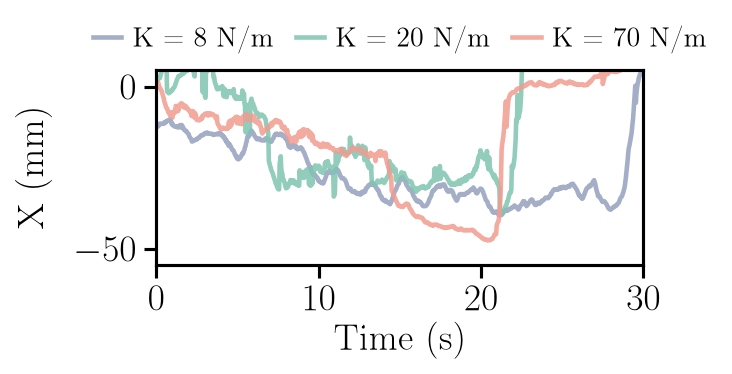

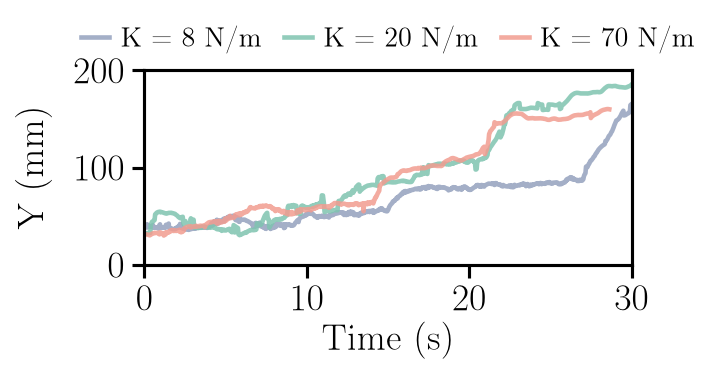

In [5]:
TRACK_LINEWIDTH = 2.2

# Axis limits -- TUNE THIS.
TRACK_XLIM = (0, 30)                         # time (s), both plots
TRACK_YLIM = {'X': (-55, 5), 'Y': (0, 200)}  # mm

# Fixed margins around the axes (inches) -- TUNE THIS. Both figures use the
# same figure size AND the same axes rectangle, and are saved without the
# style's tight bbox, so the exported files have identical dimensions and the
# plot areas line up exactly when placed side by side / stacked. The top
# margin holds the legend row (the same placement in both).
TRACK_MARGIN = dict(left=1.05, right=0.2, bottom=0.78, top=0.42)
TRACK_LEGEND_KW = dict(loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=len(k_xy),
                       frameon=False, handlelength=1.0, handletextpad=0.4, columnspacing=0.8)

# Figure size shared with the energy plot (PANEL_W x PANEL_H, first cell).
FIG_W_TRACK, FIG_H_TRACK = PANEL_W, PANEL_H
track_ax_rect = [TRACK_MARGIN['left'] / FIG_W_TRACK,
                 TRACK_MARGIN['bottom'] / FIG_H_TRACK,
                 1 - (TRACK_MARGIN['left'] + TRACK_MARGIN['right']) / FIG_W_TRACK,
                 1 - (TRACK_MARGIN['bottom'] + TRACK_MARGIN['top']) / FIG_H_TRACK]

for col, axis_name in [(1, 'X'), (2, 'Y')]:
    fig = plt.figure(figsize=(FIG_W_TRACK, FIG_H_TRACK))
    ax = fig.add_axes(track_ax_rect)
    for k in k_xy:
        ax.plot(track_cmp[k][0], track_cmp[k][col], color=xy_colors[k], linewidth=TRACK_LINEWIDTH,
                alpha=0.85, label=xy_labels[k])
    ax.set_xlim(*TRACK_XLIM)
    ax.set_ylim(*TRACK_YLIM[axis_name])
    ax.set_xlabel('Time (s)')
    ax.set_ylabel(f'{axis_name} (mm)', labelpad=YLABEL_PAD)
    ax.grid(GRID)
    ax.legend(**TRACK_LEGEND_KW)
    # 'standard' = keep the full fixed figure (bbox_inches=None would fall back
    # to the style's 'tight' crop, which trims each figure differently).
    with plt.rc_context({'savefig.bbox': 'standard'}):
        fig.savefig(os.path.join('outputs', 'surface_tracking', f'tracking_{axis_name.lower()}.pdf'))
        fig.savefig(os.path.join('outputs', 'surface_tracking', f'tracking_{axis_name.lower()}.png'), dpi=300)
    plt.show()

## Marker Tracking: XY Trajectory

Y vs X trajectory from the same `k_compare.xlsx` data, all stiffnesses overlaid and
coloured by time.

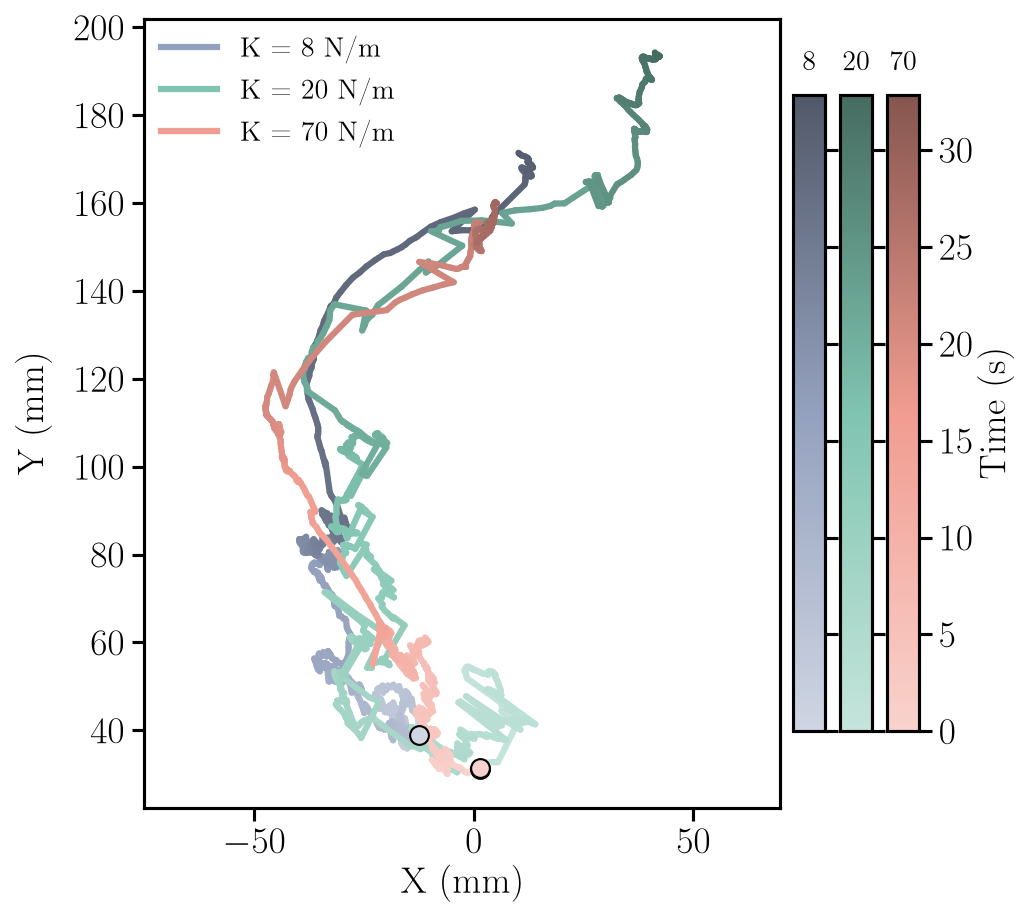

In [6]:
from matplotlib.collections import LineCollection
from matplotlib.colors import LinearSegmentedColormap, Normalize, to_rgb
from matplotlib.lines import Line2D

# XY trajectory (corrected data): Y vs X for both stiffnesses, equal axis
# scaling so the path shape isn't distorted. Colour encodes time: each run
# keeps its own hue (xy_colors) and goes light
# (start) -> dark (end), on one shared time scale. Circle = start.
XY_FIG_H     = 6.0   # inches -- TUNE THIS; width follows from the data's aspect ratio
XY_LINEWIDTH = 3.0
XY_LIGHT     = 0.55  # start-of-run tint: fraction mixed with white -- TUNE THIS
XY_DARK      = 0.45  # end-of-run shade: fraction mixed with black -- TUNE THIS
XY_LEGEND_KW = dict(loc='upper left', framealpha=0.9)  # TUNE THIS


def time_cmap(color):
    c = np.array(to_rgb(color))
    return LinearSegmentedColormap.from_list(
        f'time_{color}', [c + (1 - c) * XY_LIGHT, c, c * (1 - XY_DARK)])


xy_cmaps = {k: time_cmap(xy_colors[k]) for k in k_xy}

x_all = np.concatenate([track_cmp[k][1] for k in k_xy])
y_all = np.concatenate([track_cmp[k][2] for k in k_xy])
xy_aspect = (x_all.max() - x_all.min()) / (y_all.max() - y_all.min())
norm = Normalize(vmin=0, vmax=max(track_cmp[k][0][-1] for k in k_xy))

fig, ax = plt.subplots(figsize=(XY_FIG_H * xy_aspect + 3.5, XY_FIG_H), layout='constrained')
legend_handles = []
for k in k_xy:
    t_k, x_k, y_k = track_cmp[k]
    cmap = xy_cmaps[k]
    pts  = np.column_stack([x_k, y_k]).reshape(-1, 1, 2)
    segs = np.concatenate([pts[:-1], pts[1:]], axis=1)
    lc = LineCollection(segs, cmap=cmap, norm=norm, linewidth=XY_LINEWIDTH,
                        capstyle='round', joinstyle='round', zorder=3)
    lc.set_array(0.5 * (t_k[:-1] + t_k[1:]))
    ax.add_collection(lc)
    ax.plot(x_k[0], y_k[0], 'o', color=cmap(0.0), markersize=9, markeredgecolor='black', zorder=4)
    legend_handles.append(Line2D([], [], color=cmap(0.5), linewidth=XY_LINEWIDTH, label=xy_labels[k]))

ax.autoscale_view()
ax.set_aspect('equal', adjustable='datalim')
ax.set_xlabel('X (mm)')
ax.set_ylabel('Y (mm)', labelpad=YLABEL_PAD)
ax.grid(GRID)
ax.legend(handles=legend_handles, **XY_LEGEND_KW)

# One colorbar per stiffness (same time scale), titled with its K. constrained
# layout puts each new colorbar *between* the axes and the previous ones, so
# they're added outermost-first; only the outermost carries tick numbers and
# the 'Time (s)' label.
for i, k in enumerate(reversed(k_xy)):
    sm = plt.cm.ScalarMappable(cmap=xy_cmaps[k], norm=norm)
    cbar = fig.colorbar(sm, ax=ax, fraction=0.05, pad=0.02)
    cbar.ax.set_title(f'{k}', fontsize=LEGEND_FONT_SIZE)
    if i == 0:
        cbar.set_label('Time (s)')
    else:
        cbar.ax.tick_params(labelright=False)

fig.savefig(os.path.join('outputs', 'surface_tracking', 'k_compare_xy.pdf'))
fig.savefig(os.path.join('outputs', 'surface_tracking', 'k_compare_xy.png'), dpi=300)
plt.show()